# SEAWAT Tutorial 1: The Henry Saltwater Intrusion Problem
### SEAWAT FloPy Short Course

In this session we build a SEAWAT Version 4 model of the Henry saltwater intrusion problem with FloPy, run it, and look at the results. The code is the official FloPy example *SEAWAT Tutorial 1*. We only added the setup cells that are needed to run it on Google Colab. The step numbers match the lecture slides.

**Learning objectives**
1. Explain why seawater enters a coastal aquifer along its base as a wedge in the Henry problem.
2. Describe SEAWAT as a combination of MODFLOW (groundwater flow), MT3DMS (solute transport) and VDF (density coupling), and explain what each package does.
3. Write SEAWAT input files with FloPy and run the model.
4. Read the simulated concentration, flow and head, plot them and interpret the results.

## Step 0. Setting up the environment
Colab does not come with FloPy or the SEAWAT program (`swtv4`), so we install them first. Run the cells below once every time you connect.

The first cell is a small fix for Colab. Without it, Colab prints a warning after every cell and the model run in Step 9 may never finish. The second cell installs FloPy and downloads SEAWAT. The last three cells load the Python libraries that the tutorial uses.

In [1]:
# This cell fixes a Colab problem in which the Run Model cell never finishes,
# caused by a version conflict between Colab's Python 3.13 and the Jupyter client.

import warnings, datetime, jupyter_client.session
warnings.filterwarnings("ignore", category=DeprecationWarning)                        # hide the warnings
jupyter_client.session.utcnow = lambda: datetime.datetime.now(datetime.timezone.utc)  # replace the warning-producing function with a warning-free version

import ipykernel.kernelbase
ipykernel.kernelbase.now = jupyter_client.session.utcnow                              # also replace the copy the kernel made at start-up (otherwise the warning keeps appearing)

In [2]:
# Colab does not include FloPy or MODFLOW-family executables such as swtv4, so we install them at run time for the course.
# The installation disappears when the runtime is reset, so nothing is left on participants' computers
# (run this cell first every time).

!pip install -q "flopy<3.12"                        # install FloPy (3.11). flopy 3.12 needs numpy >= 2.2, which would upgrade the numpy that Colab already has and break numba
!get-modflow /usr/local/bin --subset swtv4 --quiet  # install the SEAWAT executable (swtv4) into /usr/local/bin, which is on the PATH

import flopy, shutil
print("FloPy", flopy.__version__, "| swtv4:", shutil.which("swtv4"))  # confirm that both are installed

FloPy 3.11.0 | swtv4: /usr/local/bin/swtv4


In [3]:
from pathlib import Path                 # file paths
from tempfile import TemporaryDirectory  # temporary working folder

In [4]:
import numpy as np    # array computations

In [5]:
import flopy          # write SEAWAT input files, run the model, read the results

## The Henry problem and SEAWAT

**Seawater intrusion.** In a coastal aquifer, fresh groundwater (about 1,000 kg/m³) flows toward the sea and meets seawater (about 1,025 kg/m³). Seawater is heavier, so it pushes inland along the base of the aquifer and forms a **saltwater wedge**. The fresh water flows over the wedge and leaves the aquifer at the sea. Between the two waters there is a **mixing zone** where the concentration changes gradually.

**The Henry problem.** Henry (1964) solved this seawater intrusion problem for a simple aquifer, and it is now widely used to test variable density groundwater models. The setup is as follows.
- A vertical section 2 m long and 1 m high, confined and homogeneous
- Left side (land): constant freshwater inflow with a concentration of 0
- Right side (sea): seawater boundary with a concentration of 35 kg/m³
- Top and bottom: no flow boundaries
- At the start the aquifer is full of seawater. Fresh water then pushes the seawater back until a balance is reached.

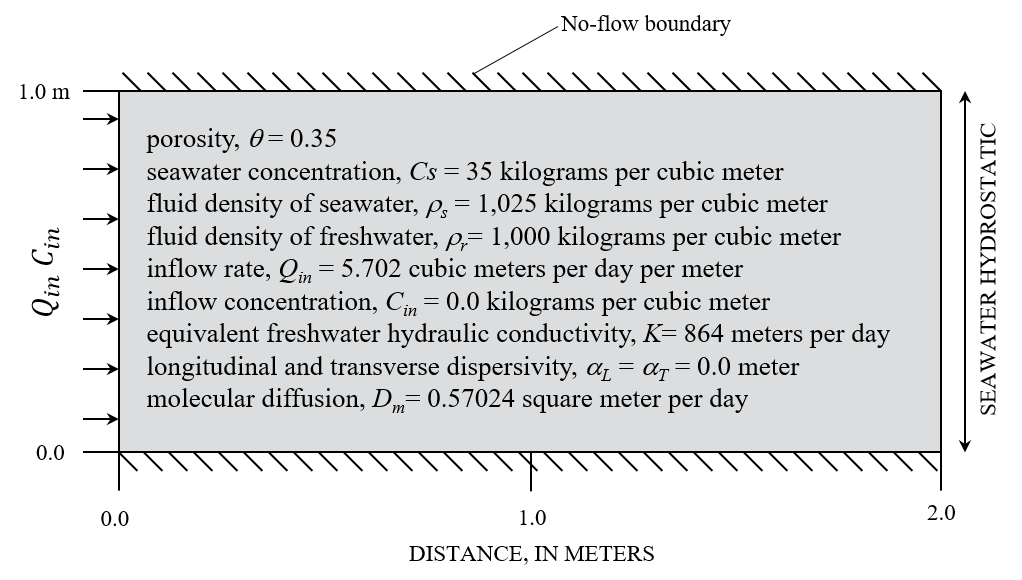
**Boundary conditions and model parameters for the Henry problem.**

**How SEAWAT is organized.** SEAWAT joins MODFLOW and MT3DMS into one program and links them through the fluid density, which changes with concentration. The table lists the packages used in this tutorial and the step in which each one is created.

<table style="width:100%; table-layout:auto; border-collapse:collapse; margin:10px 0 16px 0; font-size:0.95em;">
<thead><tr>
<th style="background:rgba(127,127,127,0.30); font-family:Arial, Helvetica, sans-serif; font-weight:700; text-align:center; vertical-align:middle; padding:6px 10px; border:none;">Program</th>
<th style="background:rgba(127,127,127,0.30); font-family:Arial, Helvetica, sans-serif; font-weight:700; text-align:center; vertical-align:middle; padding:6px 10px; border:none;">Package</th>
<th style="background:rgba(127,127,127,0.30); font-family:Arial, Helvetica, sans-serif; font-weight:700; text-align:center; vertical-align:middle; padding:6px 10px; border:none;">Acronym</th>
<th style="background:rgba(127,127,127,0.30); font-family:Arial, Helvetica, sans-serif; font-weight:700; text-align:center; vertical-align:middle; padding:6px 10px; border:none;">Role</th>
<th style="background:rgba(127,127,127,0.30); font-family:Arial, Helvetica, sans-serif; font-weight:700; text-align:center; vertical-align:middle; padding:6px 10px; border:none;">Step</th>
</tr></thead><tbody>
<tr><td rowspan="6" style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:center; vertical-align:middle; background:transparent; border-bottom:1px solid rgba(127,127,127,0.45);">MODFLOW</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:transparent; border-bottom:none;">Discretization</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:center; vertical-align:top; background:transparent; border-bottom:none;">DIS</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:transparent; border-bottom:none;">Grid and time</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:center; vertical-align:top; background:transparent; border-bottom:none;">3</td></tr>
<tr><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:rgba(127,127,127,0.13); border-bottom:none;">Basic</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:center; vertical-align:top; background:rgba(127,127,127,0.13); border-bottom:none;">BAS6</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:rgba(127,127,127,0.13); border-bottom:none;">Active and constant head cells, starting head</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:center; vertical-align:top; background:rgba(127,127,127,0.13); border-bottom:none;">4</td></tr>
<tr><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:transparent; border-bottom:none;">Layer Property Flow</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:center; vertical-align:top; background:transparent; border-bottom:none;">LPF</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:transparent; border-bottom:none;">Hydraulic conductivity</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:center; vertical-align:top; background:transparent; border-bottom:none;">5</td></tr>
<tr><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:rgba(127,127,127,0.13); border-bottom:none;">Preconditioned Conjugate Gradient</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:center; vertical-align:top; background:rgba(127,127,127,0.13); border-bottom:none;">PCG</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:rgba(127,127,127,0.13); border-bottom:none;">Flow solver</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:center; vertical-align:top; background:rgba(127,127,127,0.13); border-bottom:none;">5</td></tr>
<tr><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:transparent; border-bottom:none;">Output Control</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:center; vertical-align:top; background:transparent; border-bottom:none;">OC</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:transparent; border-bottom:none;">When to save results</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:center; vertical-align:top; background:transparent; border-bottom:none;">5</td></tr>
<tr><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:rgba(127,127,127,0.13); border-bottom:1px solid rgba(127,127,127,0.45);">Well</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:center; vertical-align:top; background:rgba(127,127,127,0.13); border-bottom:1px solid rgba(127,127,127,0.45);">WEL</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:rgba(127,127,127,0.13); border-bottom:1px solid rgba(127,127,127,0.45);">Freshwater inflow</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:center; vertical-align:top; background:rgba(127,127,127,0.13); border-bottom:1px solid rgba(127,127,127,0.45);">6</td></tr>
<tr><td rowspan="5" style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:center; vertical-align:middle; background:transparent; border-bottom:1px solid rgba(127,127,127,0.45);">MT3DMS</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:transparent; border-bottom:none;">Basic Transport</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:center; vertical-align:top; background:transparent; border-bottom:none;">BTN</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:transparent; border-bottom:none;">Porosity, initial concentration, time step</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:center; vertical-align:top; background:transparent; border-bottom:none;">7</td></tr>
<tr><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:rgba(127,127,127,0.13); border-bottom:none;">Advection</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:center; vertical-align:top; background:rgba(127,127,127,0.13); border-bottom:none;">ADV</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:rgba(127,127,127,0.13); border-bottom:none;">Advection</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:center; vertical-align:top; background:rgba(127,127,127,0.13); border-bottom:none;">7</td></tr>
<tr><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:transparent; border-bottom:none;">Dispersion</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:center; vertical-align:top; background:transparent; border-bottom:none;">DSP</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:transparent; border-bottom:none;">Dispersion and diffusion</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:center; vertical-align:top; background:transparent; border-bottom:none;">7</td></tr>
<tr><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:rgba(127,127,127,0.13); border-bottom:none;">Generalized Conjugate Gradient</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:center; vertical-align:top; background:rgba(127,127,127,0.13); border-bottom:none;">GCG</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:rgba(127,127,127,0.13); border-bottom:none;">Transport solver</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:center; vertical-align:top; background:rgba(127,127,127,0.13); border-bottom:none;">7</td></tr>
<tr><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:transparent; border-bottom:1px solid rgba(127,127,127,0.45);">Source/Sink Mixing</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:center; vertical-align:top; background:transparent; border-bottom:1px solid rgba(127,127,127,0.45);">SSM</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:transparent; border-bottom:1px solid rgba(127,127,127,0.45);">Concentrations of inflowing water and boundaries</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:center; vertical-align:top; background:transparent; border-bottom:1px solid rgba(127,127,127,0.45);">6, 7</td></tr>
<tr><td rowspan="1" style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:center; vertical-align:middle; background:transparent; border-bottom:1.5px solid currentColor;">SEAWAT</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:rgba(127,127,127,0.13); border-bottom:1.5px solid currentColor;">Variable Density Flow</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:center; vertical-align:top; background:rgba(127,127,127,0.13); border-bottom:1.5px solid currentColor;">VDF</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:rgba(127,127,127,0.13); border-bottom:1.5px solid currentColor;">Concentration → density → flow coupling</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:center; vertical-align:top; background:rgba(127,127,127,0.13); border-bottom:1.5px solid currentColor;">8</td></tr>
</tbody></table>

## How SEAWAT runs: the calculation loop
The packages above are the ingredients of the model. When we call `run_model()` in Step 9, FloPy starts the SEAWAT program, and SEAWAT puts the packages to work by following the loop in the flow chart below. FloPy itself does none of these calculations. It only writes the input files and starts SEAWAT.

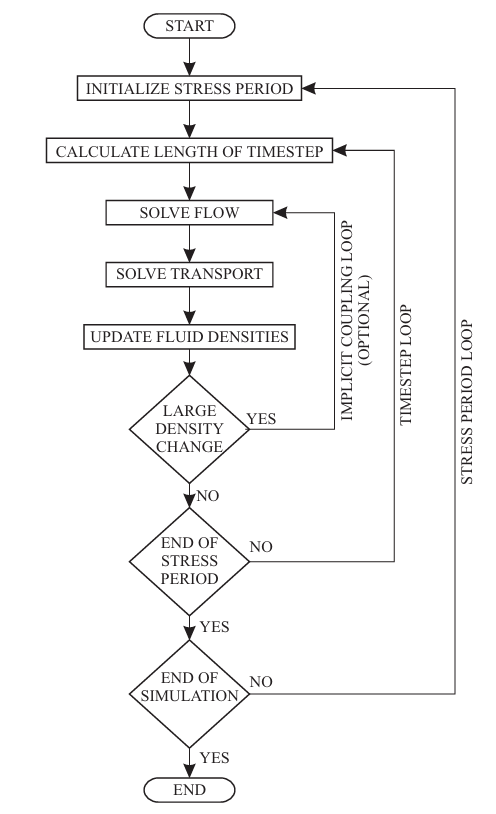

**Generalized flow chart of the SEAWAT program.**

Read the chart from the top.
1. **Initialize stress period.** SEAWAT reads the boundary conditions for the stress period, such as the freshwater inflow (WEL), the sea boundary (BAS6) and the inflow concentrations (SSM).
2. **Calculate length of timestep.** SEAWAT decides how far to move forward in time in this pass (BTN).
3. **Solve flow.** Heads and flows are calculated with the current fluid densities (BAS6, LPF, PCG, WEL).
4. **Solve transport.** The new flows move the salt forward by one timestep, and new concentrations are calculated (BTN, ADV, DSP, SSM, GCG).
5. **Update fluid densities.** The new concentrations are turned into new densities (VDF). The next flow calculation uses these densities.
6. **Large density change?** This optional check solves the same timestep again until flow and concentration agree with each other. This is called implicit coupling. Our model does not use it, so SEAWAT always goes straight on.
7. **End of stress period?** If not, SEAWAT goes back to box 2 and moves forward by another timestep.
8. **End of simulation?** If another stress period follows, SEAWAT goes back to box 1. Otherwise the run ends.

In short, SEAWAT repeats **flow → transport → density** again and again, and every pass moves the model a little further in time. Step 9 shows how many times this loop runs in our model.

## Step 1. Input variables
Before building the model, we write down its size, how finely it is divided, and its physical properties as Python variables. Keeping these numbers in one place makes the later steps easier to read, and you can change a value here and run the whole notebook again. All lengths are in metres and all times are in days. MODFLOW and MT3DMS do not convert units, so every input must use the same units.

<table style="width:100%; table-layout:auto; border-collapse:collapse; margin:10px 0 16px 0; font-size:0.95em;">
<thead><tr>
<th style="background:rgba(127,127,127,0.30); font-family:Arial, Helvetica, sans-serif; font-weight:700; text-align:center; vertical-align:middle; padding:6px 10px; border:none;">Group</th>
<th style="background:rgba(127,127,127,0.30); font-family:Arial, Helvetica, sans-serif; font-weight:700; text-align:center; vertical-align:middle; padding:6px 10px; border:none;">Variable</th>
<th style="background:rgba(127,127,127,0.30); font-family:Arial, Helvetica, sans-serif; font-weight:700; text-align:center; vertical-align:middle; padding:6px 10px; border:none;">Value</th>
<th style="background:rgba(127,127,127,0.30); font-family:Arial, Helvetica, sans-serif; font-weight:700; text-align:center; vertical-align:middle; padding:6px 10px; border:none;">Unit</th>
<th style="background:rgba(127,127,127,0.30); font-family:Arial, Helvetica, sans-serif; font-weight:700; text-align:center; vertical-align:middle; padding:6px 10px; border:none;">Description</th>
</tr></thead><tbody>
<tr><td rowspan="2" style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:middle; background:transparent; border-bottom:1px solid rgba(127,127,127,0.45);">Domain</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:center; vertical-align:top; background:transparent; border-bottom:none;"><code>Lx</code></td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:transparent; border-bottom:none;">2.0</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:center; vertical-align:top; background:transparent; border-bottom:none;">m</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:transparent; border-bottom:none;">Length of the section</td></tr>
<tr><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:center; vertical-align:top; background:rgba(127,127,127,0.13); border-bottom:1px solid rgba(127,127,127,0.45);"><code>Lz</code></td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:rgba(127,127,127,0.13); border-bottom:1px solid rgba(127,127,127,0.45);">1.0</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:center; vertical-align:top; background:rgba(127,127,127,0.13); border-bottom:1px solid rgba(127,127,127,0.45);">m</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:rgba(127,127,127,0.13); border-bottom:1px solid rgba(127,127,127,0.45);">Height of the section</td></tr>
<tr><td rowspan="6" style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:middle; background:transparent; border-bottom:1px solid rgba(127,127,127,0.45);">Grid</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:center; vertical-align:top; background:transparent; border-bottom:none;"><code>nlay</code></td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:transparent; border-bottom:none;">50</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:center; vertical-align:top; background:transparent; border-bottom:none;">none</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:transparent; border-bottom:none;">Number of layers</td></tr>
<tr><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:center; vertical-align:top; background:rgba(127,127,127,0.13); border-bottom:none;"><code>nrow</code></td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:rgba(127,127,127,0.13); border-bottom:none;">1</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:center; vertical-align:top; background:rgba(127,127,127,0.13); border-bottom:none;">none</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:rgba(127,127,127,0.13); border-bottom:none;">Number of rows (1 means a vertical 2D section)</td></tr>
<tr><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:center; vertical-align:top; background:transparent; border-bottom:none;"><code>ncol</code></td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:transparent; border-bottom:none;">100</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:center; vertical-align:top; background:transparent; border-bottom:none;">none</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:transparent; border-bottom:none;">Number of columns</td></tr>
<tr><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:center; vertical-align:top; background:rgba(127,127,127,0.13); border-bottom:none;"><code>delr</code></td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:rgba(127,127,127,0.13); border-bottom:none;"><code>Lx / ncol</code> = 0.02</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:center; vertical-align:top; background:rgba(127,127,127,0.13); border-bottom:none;">m</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:rgba(127,127,127,0.13); border-bottom:none;">Cell width</td></tr>
<tr><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:center; vertical-align:top; background:transparent; border-bottom:none;"><code>delc</code></td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:transparent; border-bottom:none;">1.0</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:center; vertical-align:top; background:transparent; border-bottom:none;">m</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:transparent; border-bottom:none;">Row width (unit width)</td></tr>
<tr><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:center; vertical-align:top; background:rgba(127,127,127,0.13); border-bottom:1px solid rgba(127,127,127,0.45);"><code>delv</code></td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:rgba(127,127,127,0.13); border-bottom:1px solid rgba(127,127,127,0.45);"><code>Lz / nlay</code> = 0.02</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:center; vertical-align:top; background:rgba(127,127,127,0.13); border-bottom:1px solid rgba(127,127,127,0.45);">m</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:rgba(127,127,127,0.13); border-bottom:1px solid rgba(127,127,127,0.45);">Layer thickness</td></tr>
<tr><td rowspan="2" style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:middle; background:transparent; border-bottom:1px solid rgba(127,127,127,0.45);">Elevation</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:center; vertical-align:top; background:transparent; border-bottom:none;"><code>henry_top</code></td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:transparent; border-bottom:none;">1.0</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:center; vertical-align:top; background:transparent; border-bottom:none;">m</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:transparent; border-bottom:none;">Elevation of the model top</td></tr>
<tr><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:center; vertical-align:top; background:rgba(127,127,127,0.13); border-bottom:1px solid rgba(127,127,127,0.45);"><code>henry_botm</code></td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:rgba(127,127,127,0.13); border-bottom:1px solid rgba(127,127,127,0.45);">0.98 → 0.0 (50 values)</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:center; vertical-align:top; background:rgba(127,127,127,0.13); border-bottom:1px solid rgba(127,127,127,0.45);">m</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:rgba(127,127,127,0.13); border-bottom:1px solid rgba(127,127,127,0.45);">Bottom elevation of each layer</td></tr>
<tr><td rowspan="3" style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:middle; background:transparent; border-bottom:1.5px solid currentColor;">Physical parameters</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:center; vertical-align:top; background:transparent; border-bottom:none;"><code>qinflow</code></td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:transparent; border-bottom:none;">5.702</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:center; vertical-align:top; background:transparent; border-bottom:none;">m³/d</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:transparent; border-bottom:none;">Freshwater inflow at the left boundary</td></tr>
<tr><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:center; vertical-align:top; background:rgba(127,127,127,0.13); border-bottom:none;"><code>dmcoef</code></td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:rgba(127,127,127,0.13); border-bottom:none;">0.57024</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:center; vertical-align:top; background:rgba(127,127,127,0.13); border-bottom:none;">m²/d</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:rgba(127,127,127,0.13); border-bottom:none;">Molecular diffusion coefficient (another case: 1.62925)</td></tr>
<tr><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:center; vertical-align:top; background:transparent; border-bottom:1.5px solid currentColor;"><code>hk</code></td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:transparent; border-bottom:1.5px solid currentColor;">864.0</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:center; vertical-align:top; background:transparent; border-bottom:1.5px solid currentColor;">m/d</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:transparent; border-bottom:1.5px solid currentColor;">Hydraulic conductivity</td></tr>
</tbody></table>

In [6]:
Lx = 2.0           # length (m)
Lz = 1.0           # height (m)
nlay = 50          # number of layers
nrow = 1           # number of rows (vertical 2-D section)
ncol = 100         # number of columns
delr = Lx / ncol   # cell width = 0.02 (m)
delc = 1.0         # row width = 1 (m)
delv = Lz / nlay   # layer thickness = 0.02 (m)
henry_top = 1.0    # elevation of the model top (m)
henry_botm = np.linspace(henry_top - delv, 0.0, nlay)   # bottom elevation of each layer (0.98 to 0.0 m)
qinflow = 5.702  # freshwater inflow (m3/day)
dmcoef = 0.57024  # Could also try 1.62925 as another case of the Henry problem (m2/day)
hk = 864.0  # hydraulic conductivity (m/day)

## Step 2. Create the SEAWAT model
In FloPy we first create an empty model object, which works like an empty folder, and then add the packages to it one by one in the following steps. Here we give the model a name, tell FloPy which program will run it (`swtv4`), and choose a working folder. The model files go into a temporary folder that is deleted in the last cell. We also choose a file number (`ipakcb`) for saving the flow between cells, which we read again in Step 11.

<table style="width:100%; table-layout:auto; border-collapse:collapse; margin:10px 0 16px 0; font-size:0.95em;">
<thead><tr>
<th style="background:rgba(127,127,127,0.30); font-family:Arial, Helvetica, sans-serif; font-weight:700; text-align:center; vertical-align:middle; padding:6px 10px; border:none;">Variable</th>
<th style="background:rgba(127,127,127,0.30); font-family:Arial, Helvetica, sans-serif; font-weight:700; text-align:center; vertical-align:middle; padding:6px 10px; border:none;">Value</th>
<th style="background:rgba(127,127,127,0.30); font-family:Arial, Helvetica, sans-serif; font-weight:700; text-align:center; vertical-align:middle; padding:6px 10px; border:none;">Description</th>
</tr></thead><tbody>
<tr><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:center; vertical-align:top; background:transparent; border-bottom:none;"><code>name</code></td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:transparent; border-bottom:none;"><code>"seawat_henry"</code></td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:transparent; border-bottom:none;">Model name (the start of every file name)</td></tr>
<tr><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:center; vertical-align:top; background:rgba(127,127,127,0.13); border-bottom:none;"><code>exe_name</code></td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:rgba(127,127,127,0.13); border-bottom:none;"><code>"swtv4"</code></td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:rgba(127,127,127,0.13); border-bottom:none;">Program that runs the model (SEAWAT Version 4)</td></tr>
<tr><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:center; vertical-align:top; background:transparent; border-bottom:none;"><code>model_ws</code></td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:transparent; border-bottom:none;"><code>workspace</code></td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:transparent; border-bottom:none;">Working folder for the model files</td></tr>
<tr><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:center; vertical-align:top; background:rgba(127,127,127,0.13); border-bottom:1.5px solid currentColor;"><code>ipakcb</code></td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:rgba(127,127,127,0.13); border-bottom:1.5px solid currentColor;">53</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:rgba(127,127,127,0.13); border-bottom:1.5px solid currentColor;">File number for saving the cell by cell flows</td></tr>
</tbody></table>

> You may see warnings such as `The program mf2005 does not exist...`. You can ignore them, because the whole calculation is done by `swtv4`.

In [7]:
temp_dir = TemporaryDirectory()    # create a temporary working folder
workspace = temp_dir.name          # path of the working folder
name = "seawat_henry"              # model name → seawat_henry.nam, seawat_henry.dis, ...
swt = flopy.seawat.Seawat(name, exe_name="swtv4", model_ws=workspace)   # SEAWAT model object
print(swt.namefile)                # name file (the model's table of contents): seawat_henry.nam

seawat_henry.nam


/usr/local/lib/python3.13/dist-packages/flopy/mbase.py:105: UserWarning: The program mf2005 does not exist or is not executable.
  warn(
/usr/local/lib/python3.13/dist-packages/flopy/mbase.py:105: UserWarning: The program mt3dms does not exist or is not executable.
  warn(


In [8]:
ipakcb = 53    # save cell fluxes to unit 53

## Step 3. DIS package: grid and time
The DIS package divides the model into cells and the simulation time into steps. Our section is cut into 50 layers and 100 columns, so every cell is 2 cm wide and 2 cm high. There is only one row because the model is a vertical slice. The simulation covers 1.5 days in one stress period, split into 15 time steps of 0.1 day. In the flow chart, DIS sets up the stress period, and BTN in Step 7 decides how finely each time step is divided.

<table style="width:100%; table-layout:auto; border-collapse:collapse; margin:10px 0 16px 0; font-size:0.95em;">
<thead><tr>
<th style="background:rgba(127,127,127,0.30); font-family:Arial, Helvetica, sans-serif; font-weight:700; text-align:center; vertical-align:middle; padding:6px 10px; border:none;">Argument</th>
<th style="background:rgba(127,127,127,0.30); font-family:Arial, Helvetica, sans-serif; font-weight:700; text-align:center; vertical-align:middle; padding:6px 10px; border:none;">Value</th>
<th style="background:rgba(127,127,127,0.30); font-family:Arial, Helvetica, sans-serif; font-weight:700; text-align:center; vertical-align:middle; padding:6px 10px; border:none;">Description</th>
</tr></thead><tbody>
<tr><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:transparent; border-bottom:none;"><code>nlay</code>, <code>nrow</code>, <code>ncol</code></td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:transparent; border-bottom:none;">50, 1, 100</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:transparent; border-bottom:none;">Number of layers, rows and columns</td></tr>
<tr><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:rgba(127,127,127,0.13); border-bottom:none;"><code>nper</code></td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:rgba(127,127,127,0.13); border-bottom:none;">1</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:rgba(127,127,127,0.13); border-bottom:none;">Number of stress periods</td></tr>
<tr><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:transparent; border-bottom:none;"><code>delr</code>, <code>delc</code></td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:transparent; border-bottom:none;">0.02 m, 1.0 m</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:transparent; border-bottom:none;">Cell width and row width</td></tr>
<tr><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:rgba(127,127,127,0.13); border-bottom:none;"><code>laycbd</code></td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:rgba(127,127,127,0.13); border-bottom:none;">0</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:rgba(127,127,127,0.13); border-bottom:none;">No confining beds between layers</td></tr>
<tr><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:transparent; border-bottom:none;"><code>top</code></td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:transparent; border-bottom:none;">1.0 m</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:transparent; border-bottom:none;">Elevation of the model top</td></tr>
<tr><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:rgba(127,127,127,0.13); border-bottom:none;"><code>botm</code></td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:rgba(127,127,127,0.13); border-bottom:none;"><code>henry_botm</code></td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:rgba(127,127,127,0.13); border-bottom:none;">Bottom elevation of each layer</td></tr>
<tr><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:transparent; border-bottom:none;"><code>perlen</code></td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:transparent; border-bottom:none;">1.5 day</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:transparent; border-bottom:none;">Length of the stress period</td></tr>
<tr><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:rgba(127,127,127,0.13); border-bottom:1.5px solid currentColor;"><code>nstp</code></td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:rgba(127,127,127,0.13); border-bottom:1.5px solid currentColor;">15</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:rgba(127,127,127,0.13); border-bottom:1.5px solid currentColor;">Number of time steps</td></tr>
</tbody></table>

In [9]:
dis = flopy.modflow.ModflowDis(
    swt,
    nlay,              # number of layers
    nrow,              # number of rows
    ncol,              # number of columns
    nper=1,            # number of stress periods
    delr=delr,         # cell width (m)
    delc=delc,         # row width (m)
    laycbd=0,          # no confining beds
    top=henry_top,     # elevation of the model top (m)
    botm=henry_botm,   # bottom elevation of each layer (m)
    perlen=1.5,        # stress-period length (day)
    nstp=15,           # number of time steps
)

## Step 4. BAS package: boundary cells and starting head
The BAS package tells MODFLOW which cells to calculate. Every cell starts as an active cell (1). We then mark the last column on the right as constant head cells (−1), which stand for the sea. The top and bottom of the model need no extra input, because MODFLOW treats any outer face without a boundary condition as a no flow boundary. The starting head is 0 m everywhere.

<table style="width:100%; table-layout:auto; border-collapse:collapse; margin:10px 0 16px 0; font-size:0.95em;">
<thead><tr>
<th style="background:rgba(127,127,127,0.30); font-family:Arial, Helvetica, sans-serif; font-weight:700; text-align:center; vertical-align:middle; padding:6px 10px; border:none;">Argument</th>
<th style="background:rgba(127,127,127,0.30); font-family:Arial, Helvetica, sans-serif; font-weight:700; text-align:center; vertical-align:middle; padding:6px 10px; border:none;">Value</th>
<th style="background:rgba(127,127,127,0.30); font-family:Arial, Helvetica, sans-serif; font-weight:700; text-align:center; vertical-align:middle; padding:6px 10px; border:none;">Description</th>
</tr></thead><tbody>
<tr><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:transparent; border-bottom:none;"><code>ibound</code></td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:center; vertical-align:top; background:transparent; border-bottom:none;">1</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:transparent; border-bottom:none;">Active cell (the head is calculated)</td></tr>
<tr><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:rgba(127,127,127,0.13); border-bottom:none;"><code>ibound[:, :, -1]</code></td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:center; vertical-align:top; background:rgba(127,127,127,0.13); border-bottom:none;">−1</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:rgba(127,127,127,0.13); border-bottom:none;">Constant head cell (right column, the sea)</td></tr>
<tr><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:transparent; border-bottom:1.5px solid currentColor;"><code>strt</code></td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:center; vertical-align:top; background:transparent; border-bottom:1.5px solid currentColor;">0</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:transparent; border-bottom:1.5px solid currentColor;">Starting head (m)</td></tr>
</tbody></table>

In [10]:
# Variables for the BAS package
ibound = np.ones((nlay, nrow, ncol), dtype=np.int32)   # make every cell active (1)
ibound[:, :, -1] = -1                                  # make the last column (the sea) constant-head (-1)

In [11]:
bas = flopy.modflow.ModflowBas(swt, ibound, 0)   # cell status (ibound), starting head 0 m

## Step 5. LPF, PCG and OC packages: conductivity, solver and output
These three packages complete the flow part of the model. LPF gives the hydraulic conductivity of the aquifer. We use the same value in the horizontal and vertical directions, so the aquifer is isotropic. PCG is the solver that calculates the heads, and `hclose` tells it how small the change in head must become before it stops. OC decides when heads and flows are written to the output files.

<table style="width:100%; table-layout:auto; border-collapse:collapse; margin:10px 0 16px 0; font-size:0.95em;">
<thead><tr>
<th style="background:rgba(127,127,127,0.30); font-family:Arial, Helvetica, sans-serif; font-weight:700; text-align:center; vertical-align:middle; padding:6px 10px; border:none;">Package</th>
<th style="background:rgba(127,127,127,0.30); font-family:Arial, Helvetica, sans-serif; font-weight:700; text-align:center; vertical-align:middle; padding:6px 10px; border:none;">Argument</th>
<th style="background:rgba(127,127,127,0.30); font-family:Arial, Helvetica, sans-serif; font-weight:700; text-align:center; vertical-align:middle; padding:6px 10px; border:none;">Value</th>
<th style="background:rgba(127,127,127,0.30); font-family:Arial, Helvetica, sans-serif; font-weight:700; text-align:center; vertical-align:middle; padding:6px 10px; border:none;">Description</th>
</tr></thead><tbody>
<tr><td rowspan="2" style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:center; vertical-align:middle; background:transparent; border-bottom:1px solid rgba(127,127,127,0.45);">LPF</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:transparent; border-bottom:none;"><code>hk</code>, <code>vka</code></td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:transparent; border-bottom:none;">864.0 m/d</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:transparent; border-bottom:none;">Horizontal and vertical conductivity (equal, so isotropic)</td></tr>
<tr><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:rgba(127,127,127,0.13); border-bottom:1px solid rgba(127,127,127,0.45);"><code>ipakcb</code></td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:rgba(127,127,127,0.13); border-bottom:1px solid rgba(127,127,127,0.45);">53</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:rgba(127,127,127,0.13); border-bottom:1px solid rgba(127,127,127,0.45);">Save the cell by cell flows</td></tr>
<tr><td rowspan="1" style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:center; vertical-align:middle; background:transparent; border-bottom:1px solid rgba(127,127,127,0.45);">PCG</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:transparent; border-bottom:1px solid rgba(127,127,127,0.45);"><code>hclose</code></td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:transparent; border-bottom:1px solid rgba(127,127,127,0.45);">10⁻⁸ m</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:transparent; border-bottom:1px solid rgba(127,127,127,0.45);">Head convergence criterion</td></tr>
<tr><td rowspan="2" style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:center; vertical-align:middle; background:transparent; border-bottom:1.5px solid currentColor;">OC</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:rgba(127,127,127,0.13); border-bottom:none;"><code>stress_period_data</code></td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:rgba(127,127,127,0.13); border-bottom:none;"><code>{(0, 0): ["save head", "save budget"]}</code></td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:rgba(127,127,127,0.13); border-bottom:none;">When to save heads and flows</td></tr>
<tr><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:transparent; border-bottom:1.5px solid currentColor;"><code>compact</code></td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:transparent; border-bottom:1.5px solid currentColor;"><code>True</code></td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:transparent; border-bottom:1.5px solid currentColor;">Save the flows in compact format</td></tr>
</tbody></table>

> **Note.** `(0, 0)` in OC means the first time step of the first stress period, which ends at **0.1 day**. The flow vectors in Step 12 and the heads in Step 13 are therefore results at 0.1 day, while the concentrations in Step 10 are at 1.5 days. To see heads and flows at 1.5 days, change `(0, 0)` to `(0, 14)`.

In [12]:
lpf = flopy.modflow.ModflowLpf(swt, hk=hk, vka=hk, ipakcb=ipakcb)   # horizontal (hk) and vertical (vka) conductivity; save cell flows

In [13]:
pcg = flopy.modflow.ModflowPcg(swt, hclose=1.0e-8)   # flow solver, head convergence criterion

In [14]:
oc = flopy.modflow.ModflowOc(
    swt,
    stress_period_data={(0, 0): ["save head", "save budget"]},   # save head and flow at (stress period, time step) = (0, 0)
    compact=True,                                                # compact format
)

## Step 6. WEL and SSM data: freshwater inflow and boundary concentrations
In this model every boundary condition has two parts, one for the water and one for the salt. WEL says how much water enters, and SSM says how much salt that water carries. Fresh water is injected evenly into all 50 cells of the left column, and its concentration is 0. Water that enters from the sea through the constant head cells has a concentration of 35 kg/m³. In this step we prepare both lists. The WEL package is created here, and the SSM package is created in Step 7.

<table style="width:100%; table-layout:auto; border-collapse:collapse; margin:10px 0 16px 0; font-size:0.95em;">
<thead><tr>
<th style="background:rgba(127,127,127,0.30); font-family:Arial, Helvetica, sans-serif; font-weight:700; text-align:center; vertical-align:middle; padding:6px 10px; border:none;">Group</th>
<th style="background:rgba(127,127,127,0.30); font-family:Arial, Helvetica, sans-serif; font-weight:700; text-align:center; vertical-align:middle; padding:6px 10px; border:none;">Item</th>
<th style="background:rgba(127,127,127,0.30); font-family:Arial, Helvetica, sans-serif; font-weight:700; text-align:center; vertical-align:middle; padding:6px 10px; border:none;">Value</th>
<th style="background:rgba(127,127,127,0.30); font-family:Arial, Helvetica, sans-serif; font-weight:700; text-align:center; vertical-align:middle; padding:6px 10px; border:none;">Description</th>
</tr></thead><tbody>
<tr><td rowspan="1" style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:center; vertical-align:middle; background:transparent; border-bottom:1px solid rgba(127,127,127,0.45);">WEL</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:transparent; border-bottom:1px solid rgba(127,127,127,0.45);">Rate</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:transparent; border-bottom:1px solid rgba(127,127,127,0.45);"><code>qinflow / nlay</code> ≈ 0.114 m³/d</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:transparent; border-bottom:1px solid rgba(127,127,127,0.45);">Fresh water injected into each cell of the left column <code>[k, 0, 0]</code></td></tr>
<tr><td rowspan="3" style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:center; vertical-align:middle; background:transparent; border-bottom:1.5px solid currentColor;">SSM</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:rgba(127,127,127,0.13); border-bottom:none;">Concentration (fresh water)</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:rgba(127,127,127,0.13); border-bottom:none;">0.0</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:rgba(127,127,127,0.13); border-bottom:none;">Concentration of the fresh water entering the left column <code>[k, 0, 0]</code></td></tr>
<tr><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:transparent; border-bottom:none;">Concentration (seawater)</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:transparent; border-bottom:none;">35.0 kg/m³</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:transparent; border-bottom:none;">Concentration of the seawater entering the right column <code>[k, 0, ncol - 1]</code></td></tr>
<tr><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:rgba(127,127,127,0.13); border-bottom:1.5px solid currentColor;">Type code</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:rgba(127,127,127,0.13); border-bottom:1.5px solid currentColor;"><code>itype["WEL"]</code> = 2, <code>itype["BAS6"]</code> = 1</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:rgba(127,127,127,0.13); border-bottom:1.5px solid currentColor;">Boundary type (well, constant head cell)</td></tr>
</tbody></table>

The cell positions are written as `[layer, row, column]`, and k goes from 0 to 49, so every layer is included.

In [15]:
itype = flopy.mt3d.Mt3dSsm.itype_dict()   # SSM type code for each boundary type
wel_data = {}
ssm_data = {}
wel_sp1 = []
ssm_sp1 = []
for k in range(nlay):                                         # for every layer
    wel_sp1.append([k, 0, 0, qinflow / nlay])                 # WEL: inject fresh water in the left column [layer, row, col, rate]
    ssm_sp1.append([k, 0, 0, 0.0, itype["WEL"]])              # SSM: concentration of the injected fresh water = 0
    ssm_sp1.append([k, 0, ncol - 1, 35.0, itype["BAS6"]])     # SSM: concentration of water entering from the sea (constant head) = 35
wel_data[0] = wel_sp1                                         # apply to stress period 0
ssm_data[0] = ssm_sp1
wel = flopy.modflow.ModflowWel(swt, stress_period_data=wel_data, ipakcb=ipakcb)

## Step 7. MT3DMS packages: salt transport
Now we describe how the salt moves. At the start the whole aquifer is filled with seawater (35 kg/m³). BTN holds the basic information such as the porosity, the initial concentration and the length of each transport step. ADV and DSP describe how the salt is carried by the flow and how it spreads. The dispersivity is zero here, so the salt spreads only by molecular diffusion, as in the original Henry problem. GCG is the solver for the transport equation, and SSM adds the inflow concentrations prepared in Step 6. Together these packages form the "Solve transport" box of the flow chart, and `dt0` sets how far each pass of the timestep loop moves forward in time.

<table style="width:100%; table-layout:auto; border-collapse:collapse; margin:10px 0 16px 0; font-size:0.95em;">
<thead><tr>
<th style="background:rgba(127,127,127,0.30); font-family:Arial, Helvetica, sans-serif; font-weight:700; text-align:center; vertical-align:middle; padding:6px 10px; border:none;">Package</th>
<th style="background:rgba(127,127,127,0.30); font-family:Arial, Helvetica, sans-serif; font-weight:700; text-align:center; vertical-align:middle; padding:6px 10px; border:none;">Argument</th>
<th style="background:rgba(127,127,127,0.30); font-family:Arial, Helvetica, sans-serif; font-weight:700; text-align:center; vertical-align:middle; padding:6px 10px; border:none;">Value</th>
<th style="background:rgba(127,127,127,0.30); font-family:Arial, Helvetica, sans-serif; font-weight:700; text-align:center; vertical-align:middle; padding:6px 10px; border:none;">Description</th>
</tr></thead><tbody>
<tr><td rowspan="5" style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:center; vertical-align:middle; background:transparent; border-bottom:1px solid rgba(127,127,127,0.45);">BTN</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:transparent; border-bottom:none;"><code>prsity</code></td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:transparent; border-bottom:none;">0.35</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:transparent; border-bottom:none;">Porosity</td></tr>
<tr><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:rgba(127,127,127,0.13); border-bottom:none;"><code>sconc</code></td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:rgba(127,127,127,0.13); border-bottom:none;">35.0 kg/m³</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:rgba(127,127,127,0.13); border-bottom:none;">Initial concentration (all seawater)</td></tr>
<tr><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:transparent; border-bottom:none;"><code>dt0</code></td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:transparent; border-bottom:none;">0.001 day</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:transparent; border-bottom:none;">Length of each transport step</td></tr>
<tr><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:rgba(127,127,127,0.13); border-bottom:none;"><code>nprs</code></td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:rgba(127,127,127,0.13); border-bottom:none;">−5</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:rgba(127,127,127,0.13); border-bottom:none;">Save the concentrations every 5 transport steps</td></tr>
<tr><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:transparent; border-bottom:1px solid rgba(127,127,127,0.45);"><code>ifmtcn</code>, <code>chkmas</code>, <code>nprobs</code>, <code>nprmas</code></td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:transparent; border-bottom:1px solid rgba(127,127,127,0.45);">0, <code>False</code>, 10, 10</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:transparent; border-bottom:1px solid rgba(127,127,127,0.45);">Output settings</td></tr>
<tr><td rowspan="1" style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:center; vertical-align:middle; background:transparent; border-bottom:1px solid rgba(127,127,127,0.45);">ADV</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:rgba(127,127,127,0.13); border-bottom:1px solid rgba(127,127,127,0.45);"><code>mixelm</code></td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:rgba(127,127,127,0.13); border-bottom:1px solid rgba(127,127,127,0.45);">0</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:rgba(127,127,127,0.13); border-bottom:1px solid rgba(127,127,127,0.45);">Advection method (finite difference)</td></tr>
<tr><td rowspan="3" style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:center; vertical-align:middle; background:transparent; border-bottom:1px solid rgba(127,127,127,0.45);">DSP</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:transparent; border-bottom:none;"><code>al</code></td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:transparent; border-bottom:none;">0.0</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:transparent; border-bottom:none;">Longitudinal dispersivity (0 means molecular diffusion only)</td></tr>
<tr><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:rgba(127,127,127,0.13); border-bottom:none;"><code>trpt</code>, <code>trpv</code></td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:rgba(127,127,127,0.13); border-bottom:none;">1.0, 1.0</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:rgba(127,127,127,0.13); border-bottom:none;">Ratios of transverse to longitudinal dispersivity</td></tr>
<tr><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:transparent; border-bottom:1px solid rgba(127,127,127,0.45);"><code>dmcoef</code></td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:transparent; border-bottom:1px solid rgba(127,127,127,0.45);">0.57024 m²/d</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:transparent; border-bottom:1px solid rgba(127,127,127,0.45);">Molecular diffusion coefficient</td></tr>
<tr><td rowspan="3" style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:center; vertical-align:middle; background:transparent; border-bottom:1px solid rgba(127,127,127,0.45);">GCG</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:rgba(127,127,127,0.13); border-bottom:none;"><code>iter1</code>, <code>mxiter</code></td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:rgba(127,127,127,0.13); border-bottom:none;">500, 1</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:rgba(127,127,127,0.13); border-bottom:none;">Maximum inner and outer iterations</td></tr>
<tr><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:transparent; border-bottom:none;"><code>isolve</code></td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:transparent; border-bottom:none;">1</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:transparent; border-bottom:none;">Solver option (Jacobi)</td></tr>
<tr><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:rgba(127,127,127,0.13); border-bottom:1px solid rgba(127,127,127,0.45);"><code>cclose</code></td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:rgba(127,127,127,0.13); border-bottom:1px solid rgba(127,127,127,0.45);">10⁻⁷</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:rgba(127,127,127,0.13); border-bottom:1px solid rgba(127,127,127,0.45);">Concentration convergence criterion</td></tr>
<tr><td rowspan="1" style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:center; vertical-align:middle; background:transparent; border-bottom:1.5px solid currentColor;">SSM</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:transparent; border-bottom:1.5px solid currentColor;"><code>stress_period_data</code></td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:transparent; border-bottom:1.5px solid currentColor;"><code>ssm_data</code></td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:transparent; border-bottom:1.5px solid currentColor;">Concentration data from Step 6</td></tr>
</tbody></table>

In [16]:
btn = flopy.mt3d.Mt3dBtn(
    swt,
    nprs=-5,          # output frequency (every 5 transport steps)
    prsity=0.35,      # porosity
    sconc=35.0,       # initial concentration (kg/m³): the aquifer is all seawater
    ifmtcn=0,         # do not print concentrations to the listing file
    chkmas=False,     # do not write the mass-budget file
    nprobs=10,        # observation-point output frequency
    nprmas=10,        # mass-budget output frequency
    dt0=0.001,        # transport time step (day)
)
adv = flopy.mt3d.Mt3dAdv(swt, mixelm=0)                                   # advection: finite difference
dsp = flopy.mt3d.Mt3dDsp(swt, al=0.0, trpt=1.0, trpv=1.0, dmcoef=dmcoef)   # dispersion/diffusion: zero dispersivity, diffusion coefficient
gcg = flopy.mt3d.Mt3dGcg(swt, iter1=500, mxiter=1, isolve=1, cclose=1e-7)  # transport solver
ssm = flopy.mt3d.Mt3dSsm(swt, stress_period_data=ssm_data)                # inflow concentrations (Step 6)

## Step 8. VDF package: density coupling
VDF is the package that makes SEAWAT more than MODFLOW and MT3DMS running side by side. After each transport step it turns the new concentrations into densities with the equation below, and the next flow calculation uses these densities. This is the "Update fluid densities" box in the flow chart.

$$\rho = 1000 + 0.7143 \times C$$

For seawater with C = 35 kg/m³ the density is about 1,025 kg/m³. The slope 0.7143 is simply (1025 − 1000) / 35.

<table style="width:100%; table-layout:auto; border-collapse:collapse; margin:10px 0 16px 0; font-size:0.95em;">
<thead><tr>
<th style="background:rgba(127,127,127,0.30); font-family:Arial, Helvetica, sans-serif; font-weight:700; text-align:center; vertical-align:middle; padding:6px 10px; border:none;">Argument</th>
<th style="background:rgba(127,127,127,0.30); font-family:Arial, Helvetica, sans-serif; font-weight:700; text-align:center; vertical-align:middle; padding:6px 10px; border:none;">Value</th>
<th style="background:rgba(127,127,127,0.30); font-family:Arial, Helvetica, sans-serif; font-weight:700; text-align:center; vertical-align:middle; padding:6px 10px; border:none;">Description</th>
</tr></thead><tbody>
<tr><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:transparent; border-bottom:none;"><code>iwtable</code></td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:center; vertical-align:top; background:transparent; border-bottom:none;">0</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:transparent; border-bottom:none;">No water table correction (confined aquifer)</td></tr>
<tr><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:rgba(127,127,127,0.13); border-bottom:none;"><code>densemin</code>, <code>densemax</code></td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:center; vertical-align:top; background:rgba(127,127,127,0.13); border-bottom:none;">0, 0</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:rgba(127,127,127,0.13); border-bottom:none;">No lower or upper limit on the density</td></tr>
<tr><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:transparent; border-bottom:none;"><code>denseref</code></td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:center; vertical-align:top; background:transparent; border-bottom:none;">1000.0 kg/m³</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:transparent; border-bottom:none;">Density of fresh water</td></tr>
<tr><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:rgba(127,127,127,0.13); border-bottom:none;"><code>denseslp</code></td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:center; vertical-align:top; background:rgba(127,127,127,0.13); border-bottom:none;">0.7143</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:rgba(127,127,127,0.13); border-bottom:none;">Increase in density per unit of concentration</td></tr>
<tr><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:transparent; border-bottom:1.5px solid currentColor;"><code>firstdt</code></td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:center; vertical-align:top; background:transparent; border-bottom:1.5px solid currentColor;">0.001 day</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:transparent; border-bottom:1.5px solid currentColor;">Length of the first time step</td></tr>
</tbody></table>

In [17]:
vdf = flopy.seawat.SeawatVdf(
    swt,
    iwtable=0,          # no water-table correction
    densemin=0,         # no lower density limit
    densemax=0,         # no upper density limit
    denseref=1000.0,    # freshwater density (kg/m³)
    denseslp=0.7143,    # density increase per unit concentration: (1025 - 1000) / 35
    firstdt=1e-3,       # first time step (day)
)

## Step 9. Write the input files and run SEAWAT
`write_input()` saves every package as a text input file that SEAWAT can read. `run_model()` then starts SEAWAT, which works through the calculation loop shown in the flow chart before Step 1. The run takes only a few seconds. If SEAWAT does not finish normally, the `assert` line stops the notebook with an error message.

**How many times does the loop run?** The table connects each part of the flow chart with the settings of this model.

<table style="width:100%; table-layout:auto; border-collapse:collapse; margin:10px 0 16px 0; font-size:0.95em;">
<thead><tr>
<th style="background:rgba(127,127,127,0.30); font-family:Arial, Helvetica, sans-serif; font-weight:700; text-align:center; vertical-align:middle; padding:6px 10px; border:none;">Flow chart step</th>
<th style="background:rgba(127,127,127,0.30); font-family:Arial, Helvetica, sans-serif; font-weight:700; text-align:center; vertical-align:middle; padding:6px 10px; border:none;">In this example</th>
<th style="background:rgba(127,127,127,0.30); font-family:Arial, Helvetica, sans-serif; font-weight:700; text-align:center; vertical-align:middle; padding:6px 10px; border:none;">Set by</th>
</tr></thead><tbody>
<tr><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:transparent; border-bottom:none;">Stress period loop</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:transparent; border-bottom:none;">Runs once, because there is one stress period of 1.5 days</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:transparent; border-bottom:none;">DIS <code>nper=1</code>, <code>perlen=1.5</code></td></tr>
<tr><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:rgba(127,127,127,0.13); border-bottom:none;">Timestep loop</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:rgba(127,127,127,0.13); border-bottom:none;">Runs about 1,500 times. Each pass moves forward 0.001 day, so each 0.1 day MODFLOW time step is split into about 100 passes</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:rgba(127,127,127,0.13); border-bottom:none;">BTN <code>dt0</code>, VDF <code>firstdt</code>, DIS <code>nstp</code></td></tr>
<tr><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:transparent; border-bottom:none;">Solve flow</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:transparent; border-bottom:none;">Heads and flows with the current densities</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:transparent; border-bottom:none;">BAS6, LPF, PCG, WEL</td></tr>
<tr><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:rgba(127,127,127,0.13); border-bottom:none;">Solve transport</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:rgba(127,127,127,0.13); border-bottom:none;">New concentrations from those flows</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:rgba(127,127,127,0.13); border-bottom:none;">BTN, ADV, DSP, SSM, GCG</td></tr>
<tr><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:transparent; border-bottom:none;">Update fluid densities</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:transparent; border-bottom:none;">ρ = 1000 + 0.7143 × C</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:transparent; border-bottom:none;">VDF <code>denseref</code>, <code>denseslp</code></td></tr>
<tr><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:rgba(127,127,127,0.13); border-bottom:1.5px solid currentColor;">Implicit coupling loop (optional)</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:rgba(127,127,127,0.13); border-bottom:1.5px solid currentColor;">Not used. Flow and transport are coupled once in every pass (explicit coupling)</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:rgba(127,127,127,0.13); border-bottom:1.5px solid currentColor;">VDF <code>nswtcpl</code> (FloPy default 1)</td></tr>
</tbody></table>

> You can check this in the SEAWAT listing file (`seawat_henry.list`). It says `COUPLING BETWEEN FLOW AND TRANSPORT IS EXPLICIT`, and the flow equation is solved about 1,500 times, once in every pass.

In [18]:
swt.write_input()    # write the input files (.nam, .dis, .bas, ...)

In [19]:
success, buff = swt.run_model(silent=True, report=True)   # run SEAWAT (screen output is stored in buff)
assert success, "SEAWAT did not terminate normally."      # check for normal termination

## Postprocessing
SEAWAT saves its results in binary files. They cannot be opened in a text editor, so we read them with the `binaryfile` module of FloPy. The table shows which file holds which result.

<table style="width:100%; table-layout:auto; border-collapse:collapse; margin:10px 0 16px 0; font-size:0.95em;">
<thead><tr>
<th style="background:rgba(127,127,127,0.30); font-family:Arial, Helvetica, sans-serif; font-weight:700; text-align:center; vertical-align:middle; padding:6px 10px; border:none;">File</th>
<th style="background:rgba(127,127,127,0.30); font-family:Arial, Helvetica, sans-serif; font-weight:700; text-align:center; vertical-align:middle; padding:6px 10px; border:none;">Contents</th>
<th style="background:rgba(127,127,127,0.30); font-family:Arial, Helvetica, sans-serif; font-weight:700; text-align:center; vertical-align:middle; padding:6px 10px; border:none;">Read with</th>
<th style="background:rgba(127,127,127,0.30); font-family:Arial, Helvetica, sans-serif; font-weight:700; text-align:center; vertical-align:middle; padding:6px 10px; border:none;">Step</th>
</tr></thead><tbody>
<tr><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:transparent; border-bottom:none;"><code>MT3D001.UCN</code></td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:transparent; border-bottom:none;">Concentration</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:transparent; border-bottom:none;"><code>bf.UcnFile</code></td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:center; vertical-align:top; background:transparent; border-bottom:none;">10</td></tr>
<tr><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:rgba(127,127,127,0.13); border-bottom:none;"><code>seawat_henry.cbc</code></td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:rgba(127,127,127,0.13); border-bottom:none;">Cell by cell flow</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:rgba(127,127,127,0.13); border-bottom:none;"><code>bf.CellBudgetFile</code></td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:center; vertical-align:top; background:rgba(127,127,127,0.13); border-bottom:none;">11</td></tr>
<tr><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:transparent; border-bottom:1.5px solid currentColor;"><code>seawat_henry.hds</code></td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:transparent; border-bottom:1.5px solid currentColor;">Head</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:transparent; border-bottom:1.5px solid currentColor;"><code>bf.HeadFile</code></td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:center; vertical-align:top; background:transparent; border-bottom:1.5px solid currentColor;">13</td></tr>
</tbody></table>

In [20]:
import numpy as np

In [21]:
import flopy.utils.binaryfile as bf    # read binary output files

## Step 10. Load the concentrations
The concentration file holds 300 snapshots, because BTN saves the concentration every 5 transport steps. We list the saved times and keep the last one (1.5 days), which is the steady state result. The result is a 3D array with the shape (layer, row, column).

In [22]:
ucnobj = bf.UcnFile(Path(workspace) / "MT3D001.UCN", model=swt)   # open the concentration file
times = ucnobj.get_times()                                       # list of saved times
concentration = ucnobj.get_data(totim=times[-1])                 # concentration at the last time (1.5 d)

## Step 11. Load the cell by cell flows
To draw flow arrows we need the flow through each cell face. The budget file stores the flow through the right face and the lower face of every cell. MODFLOW counts flow through the lower face as positive when water moves down, so we flip its sign (`-qz`) for the plot, where up is positive.

In [23]:
cbbobj = bf.CellBudgetFile(Path(workspace) / f"{name}.cbc")          # open the flow file
times = cbbobj.get_times()                                          # saved times (0.1 d with this OC setting)
qx = cbbobj.get_data(text="flow right face", totim=times[-1])[0]    # x-direction flow (right face)
qy = np.zeros((nlay, nrow, ncol), dtype=float)                      # y-direction flow = 0 (one row)
qz = cbbobj.get_data(text="flow lower face", totim=times[-1])[0]    # z-direction flow (lower face, + downward)

## Step 12. Plot the concentrations and flow vectors
We draw a vertical cross section along the only row of the model. The colours show the concentration and the white arrows show the direction and size of the flow. An arrow is drawn in every third cell so that the picture stays readable.

In [24]:
import matplotlib.pyplot as plt    # plotting

Text(0.5, 1.0, 'Simulated Concentrations')

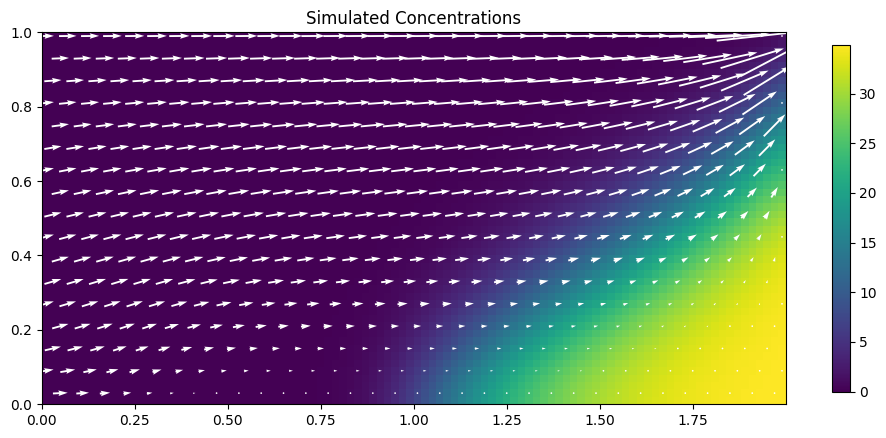

In [25]:
fig = plt.figure(figsize=(12, 9))
ax = fig.add_subplot(1, 1, 1, aspect="equal")
pmv = flopy.plot.PlotCrossSection(model=swt, ax=ax, line={"row": 0})   # vertical section along row 0
arr = pmv.plot_array(concentration)                                   # concentration (colours)
pmv.plot_vector(qx, qy, -qz, color="white", kstep=3, hstep=3)          # flow vectors (every third cell)
plt.colorbar(arr, shrink=0.5, ax=ax)                                  # colour bar
ax.set_title("Simulated Concentrations")

**Reading the figure**
- Yellow is seawater. It has entered from the lower right along the base of the aquifer and forms a wedge, because seawater is heavier than fresh water.
- Fresh water (purple) comes in from the left, flows over the wedge and leaves through the upper right.
- The colours show the result at 1.5 days and the arrows show the result at 0.1 day. See the note in Step 5.

## Step 12. Load and plot the heads
Finally we read the heads and draw them with colours and contour lines. Because of the OC setting in Step 5, these heads are the result at 0.1 day.

In [26]:
headobj = bf.HeadFile(Path(workspace) / f"{name}.hds")   # open the head file
times = headobj.get_times()                              # saved times (0.1 d with this OC setting)
head = headobj.get_data(totim=times[-1])                 # heads

Text(0.5, 1.0, 'Simulated Heads')

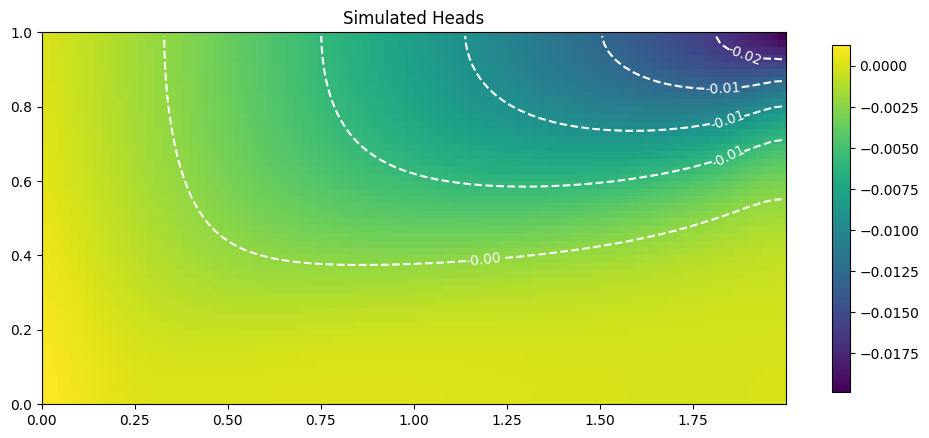

In [27]:
fig = plt.figure(figsize=(12, 9))
ax = fig.add_subplot(1, 1, 1, aspect="equal")
pmv = flopy.plot.PlotCrossSection(model=swt, ax=ax, line={"row": 0})   # vertical section along row 0
arr = pmv.plot_array(head)                                            # head (colours)
contours = pmv.contour_array(head, colors="white")                    # head contours
ax.clabel(contours, fmt="%2.2f")                                      # contour labels
plt.colorbar(arr, shrink=0.5, ax=ax)                                  # colour bar
ax.set_title("Simulated Heads")

**Reading the figure**
- The head is highest on the left (land) and lowest at the upper right, where fresh water leaves the model. This difference in head drives the fresh water toward the sea.
- SEAWAT reports **equivalent freshwater heads**, which means the pressure is converted to a head as if the water were fresh. Where heavy seawater is present, water does not simply flow at right angles to the head contours.

## Clean up
This cell deletes the temporary working folder created in Step 2.

In [28]:
try:
    temp_dir.cleanup()    # delete the temporary working folder
except:
    # prevent windows permission error
    pass

## Summary
- SEAWAT = MODFLOW (groundwater flow) + MT3DMS (solute transport) + VDF (density coupling).
- With FloPy we create the model, add the packages, write the input files with `write_input()`, run SEAWAT with `run_model()`, and read the results back for plotting.
- SEAWAT repeats flow, transport and density updates in small time steps until the end of the simulation.
- In the Henry problem, the density difference makes seawater enter along the base of the aquifer as a wedge.

**Going further**
1. Change `dmcoef` in Step 1 to 1.62925, run again, and compare the shape of the wedge.
2. Halve `qinflow` in Step 1 (2.851). Which way does the wedge move?

**References**
- FloPy Documentation, *SEAWAT Tutorial 1: Henry Saltwater Intrusion Problem*. https://flopy.readthedocs.io/en/3.3.5/_notebooks/tutorial01_seawat.html
- Langevin, C. D., et al. (2008). *SEAWAT Version 4: A computer program for simulation of multi-species solute and heat transport*. USGS Techniques and Methods 6-A22.
- Henry, H. R. (1964). Effects of dispersion on salt encroachment in coastal aquifers. USGS Water-Supply Paper 1613-C.
- Bakker, M., et al. (2016). Scripting MODFLOW model development using Python and FloPy. *Groundwater*, 54(5), 733–739.